# 07 Wintervergleich der Begehungen

- Wirkung der Begehungen auf den Rücklauf: Heizperiode vor gegen Heizperiode nach der Begehung, je Station.
- Kurze Fenster (21 gegen 21 Tage, Notebook 03) messen den Jahresgang mit; zwei Heizperioden decken dieselben Kalendermonate ab, ohne Vorjahresversatz und ohne den Sommer.
- Winterabgrenzung aus `src/season.py`, Logik in `src/jahresvergleich.py`, Tests in `tests/test_jahresvergleich.py`.

## 1 · Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import jahresvergleich as jv
from src import load_begehungen as lb
from src import nb00_daten as nb00
from src import season
from src import weather

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 4)

### Parameter

- `VARIANTE`: Winterabgrenzung der Hauptauswertung, `VARIANTE_SENS`: Gegenprobe mit Übergangsmonaten (Abschnitt 11); beide aus `season.SEASON_MONTHS`.

In [2]:
VARIANTE = jv.WINTER_KERN          #Dezember bis Februar
VARIANTE_SENS = jv.WINTER_ERWEITERT  #September bis April, Sensitivitaet

MIN_TAGESABDECKUNG = 0.6   #Anteil der Kalendertage mit mindestens einem Messwert
MIN_COVERAGE = 0.6         #Stundenabdeckung, nur als strengere Gegenprobe
MIN_FENSTERANTEIL = 0.6    #wieviel der Heizperiode nach dem Beschneiden bleibt
RT_SCHWELLE = jv.RT_SCHWELLE

#Vorstufe: Fensterlaengen des gescheiterten Jahresvergleichs
KANDIDATEN_L = [365, 330, 300, 270, 240, 210, 180, 120]
ALT_HAUPT_L = 270
ALT_ZWEIT_L = 180

for name, (m_start, m_end) in sorted(jv.WINTER_VARIANTEN.items()):
    print(f"{name:10s}: Monat {m_start:2d} bis Monat {m_end} des Folgejahres")
for seg in (season.KERNWINTER, season.UEBERGANG_FRUEH, season.UEBERGANG_SPAET):
    monate = sorted(m for m, s in season.SEASON_MONTHS.items() if s == seg)
    print(f"season.py {seg:16s}: Monate {monate}")

erweitert : Monat  9 bis Monat 4 des Folgejahres
kernwinter: Monat 12 bis Monat 2 des Folgejahres
season.py kernwinter      : Monate [1, 2, 12]
season.py uebergang_frueh : Monate [9, 10, 11]
season.py uebergang_spaet : Monate [3, 4]


## 2 · Daten laden

- Stundenreihen aus Notebook 00 über `src/nb00_daten.py`; fünf Zähler mit ODS-Nachlieferung bis Juli 2026, alle anderen bis 11.07.2025.
- Bei den fünf fehlen ab Mai 2024 gemessene Energie- und Volumenstände, `lade_serien` integriert sie aus Leistung und Durchfluss.

In [3]:
#Stundenreihen aus Notebook 00 (data/processed/real_meters)
serien = nb00.lade_serien()
ladefehler = nb00.nicht_aufbereitet()
historien = {z: (d.index[0].normalize(), d.index[-1].normalize())
             for z, d in serien.items() if len(d)}
hist_von = min(v[0] for v in historien.values())
hist_bis = max(v[1] for v in historien.values())

print(f"{len(serien)} Zaehlerreihen aus Notebook 00, "
      f"{len(ladefehler)} dort nicht aufbereitet")
if len(ladefehler):
    display(ladefehler)
print(f"Historie insgesamt: {hist_von.date()} .. {hist_bis.date()} "
      f"({(hist_bis - hist_von).days} Tage)")

100 Zaehlerreihen aus Notebook 00, 1 dort nicht aufbereitet


,meter,dateien,grund
0,81050517,81050517_2025n.csv,"von NB 00 übersprungen (siehe dort, Abschnitt 2)"


Historie insgesamt: 2021-05-31 .. 2026-07-20 (1876 Tage)


In [4]:
#Heizgradstunden bis ueber das Ende der Nachlieferung (Juli 2026) hinaus
t_out = weather.load_outdoor_temperature(hist_von,
                                         pd.Timestamp("2026-08-01"),
                                         allow_download=False)
hdh = weather.heating_degree_hours(t_out)
print(f"Aussentemperatur: {len(t_out)} Stunden, "
      f"{int(t_out['interpolated'].sum())} davon interpoliert")
print(f"Heizgradstunden gesamt: {hdh.sum():,.0f} Kh "
      f"(Heizgrenze {15.0:.0f} °C)")

Aussentemperatur: 45308 Stunden, 7 davon interpoliert
Heizgradstunden gesamt: 245,129 Kh (Heizgrenze 15 °C)


In [5]:
begehungen = (lb.begehungen_mit_zaehler(available=set(serien))
                .dropna(subset=["meter", "datum"]))
begehungen["meter"] = begehungen["meter"].astype(int)
begehungen_je_meter = lb.begehung_dates_by_meter(available=set(serien))
zaehlerwechsel = lb.meter_changes()

print(f"{len(begehungen)} Begehungen mit Zaehlernummer und Datum, "
      f"{begehungen['meter'].nunique()} Zaehler")
print(f"Begehungszeitraum: {begehungen['datum'].min().date()} .. "
      f"{begehungen['datum'].max().date()}")
print(f"Zaehler mit mehr als einer Begehung: "
      f"{sum(len(v) > 1 for v in begehungen_je_meter.values())}")
display(begehungen["datum"].dt.to_period("M").value_counts().sort_index()
        .rename("begehungen").to_frame())

58 Begehungen mit Zaehlernummer und Datum, 56 Zaehler
Begehungszeitraum: 2024-08-26 .. 2025-09-16
Zaehler mit mehr als einer Begehung: 2


,begehungen
datum,
2024-08,2
2024-09,34
2024-10,3
2024-11,13
2024-12,1
2025-03,1
2025-09,4


## 3 · Vorstufe: warum nicht das volle Jahr

- Der Vorjahresvergleich über ein langes Fenster ist an der Datenlage gescheitert.

In [6]:
uebersicht = []
for L in KANDIDATEN_L:
    a = jv.abdeckung(begehungen, historien, L)
    uebersicht.append({
        "fenster_tage": L,
        "begehungen_gesamt": len(a),
        "beide_fenster_vollstaendig": int(a["vollstaendig"].sum()),
        "zaehler": int(a.loc[a["vollstaendig"], "meter"].nunique()),
    })
display(pd.DataFrame(uebersicht))

machbar = jv.abdeckung(begehungen, historien, ALT_HAUPT_L)
print(f"maximal verfuegbare Tage nach einer Begehung: "
      f"{machbar['tage_danach'].max():.0f}")
print(f"Median Tage danach: {machbar['tage_danach'].median():.0f}, "
      f"Median Tage davor: {machbar['tage_davor'].median():.0f}")

,fenster_tage,begehungen_gesamt,beide_fenster_vollstaendig,zaehler
0,365,58,2,2
1,330,58,2,2
2,300,58,15,15
3,270,58,34,34
4,240,58,38,37
5,210,58,44,43
6,180,58,44,43
7,120,58,46,45


maximal verfuegbare Tage nach einer Begehung: 678
Median Tage danach: 295, Median Tage davor: 539


- ein volles Jahr danach nur für 2 der 58 Begehungen, beide an Zählern mit Nachlieferung
- alle anderen Zähler enden am 11.07.2025, früheste Begehung 26.08.2024, also höchstens 319 Tage
- Fallzahl je Fensterlänge: 330 Tage 2, 270 Tage 34, 180 Tage 44
- 270 Tage mit Vorjahresversatz: 24 auswertbare Begehungen, aber der halbe Sommer im Fenster

## 4 · Winterzuordnung und Fenster

- Anker ist immer der Kernwinter Dezember bis Februar, auch bei erweiterter Abgrenzung.
- Begehung zwischen zwei Kernwintern: die beiden benachbarten (September 2024: 2023/24 gegen 2024/25).
- Begehung im Kernwinter: dieser fällt heraus, verglichen werden der davor und der danach.

In [7]:
zuordnung = pd.DataFrame([
    {"beispiel": t,
     **{k: v for k, v in jv.winterzuordnung(t).items()
        if k in ("winter_vor_label", "winter_nach_label", "angeschnitten")}}
    for t in ["2024-08-26", "2024-09-16", "2024-11-15", "2024-12-02",
              "2025-01-20", "2025-03-05", "2025-09-11"]
])
display(zuordnung)

beg_z = begehungen.assign(
    **pd.DataFrame([jv.winterzuordnung(d) for d in begehungen["datum"]],
                   index=begehungen.index)[
        ["winter_vor_label", "winter_nach_label", "angeschnitten"]])
print(f"{int(beg_z['angeschnitten'].sum())} von {len(beg_z)} Begehungen fallen "
      f"in einen Kernwinter und verlieren ihn als Vergleichsfenster")
display(beg_z.loc[beg_z["angeschnitten"],
                  ["meter", "datum", "winter_vor_label", "winter_nach_label"]]
        .assign(datum=lambda d: d["datum"].dt.date))
display(beg_z.groupby(["winter_vor_label", "winter_nach_label"])
        .size().rename("begehungen").to_frame())

,beispiel,winter_vor_label,winter_nach_label,angeschnitten
0,2024-08-26,2023/24,2024/25,False
1,2024-09-16,2023/24,2024/25,False
2,2024-11-15,2023/24,2024/25,False
3,2024-12-02,2023/24,2025/26,True
4,2025-01-20,2023/24,2025/26,True
5,2025-03-05,2024/25,2025/26,False
6,2025-09-11,2024/25,2025/26,False


1 von 58 Begehungen fallen in einen Kernwinter und verlieren ihn als Vergleichsfenster


,meter,datum,winter_vor_label,winter_nach_label
11,72135443,2024-12-02,2023/24,2025/26


begehungen
winter_vor_label winter_nach_label            
2023/24          2024/25                    52
                 2025/26                     1
2024/25          2025/26                     5

In [8]:
#Gegenprobe zur Kalendergleichheit: decken beide Fenster dieselben
#Kalendermonate ab, ohne dass ein Vorjahresversatz noetig waere?
zeilen = []
for name in (VARIANTE, VARIANTE_SENS):
    for tag in ("2024-09-16", "2024-11-15", "2025-09-11"):
        f = jv.winterfenster(tag, name)
        mon_vor = sorted({d.month for d in pd.date_range(f["vor_start"],
                                                         f["vor_end"], freq="D")})
        mon_nach = sorted({d.month for d in pd.date_range(f["nach_start"],
                                                          f["nach_end"], freq="D")})
        zeilen.append({"variante": name, "begehung": tag,
                       "vor": f"{f['vor_start'].date()}..{f['vor_end'].date()}",
                       "nach": f"{f['nach_start'].date()}..{f['nach_end'].date()}",
                       "monate_gleich": mon_vor == mon_nach,
                       "fensteranteil": round(f["fensteranteil"], 3)})
display(pd.DataFrame(zeilen))

,variante,begehung,vor,nach,monate_gleich,fensteranteil
0,kernwinter,2024-09-16,2023-12-01..2024-02-29,2024-12-01..2025-02-28,True,1.000
1,kernwinter,2024-11-15,2023-12-01..2024-02-29,2024-12-01..2025-02-28,True,1.000
2,kernwinter,2025-09-11,2024-12-01..2025-02-28,2025-12-01..2026-02-28,True,1.000
3,erweitert,2024-09-16,2023-09-17..2024-04-30,2024-09-17..2025-04-30,True,0.934
4,erweitert,2024-11-15,2023-11-16..2024-04-30,2024-11-16..2025-04-30,True,0.686
5,erweitert,2025-09-11,2024-09-12..2025-04-30,2025-09-12..2026-04-30,True,0.955


- `monate_gleich`: beide Fenster über dieselben Kalendermonate.
- `fensteranteil`: verbleibender Teil der Heizperiode, wenn die Begehung in ein Fenster ragt (nur bei erweiterter Abgrenzung; derselbe Ausschnitt fällt dann in beiden Fenstern weg); unter `MIN_FENSTERANTEIL` fällt der Fall heraus.

## 5 · Abdeckung und Ausschlussbilanz

- Schwelle für die Abdeckung als Parameter, jeder Ausschluss mit Grund in der Tabelle.

In [9]:
def winter_auswertung(variante, serien_, historien_, begehungen_,
                      min_tagesabdeckung=MIN_TAGESABDECKUNG,
                      min_coverage=0.0):
    """Wintertabelle plus Ausschlussgrund je Zeile."""
    tab = jv.wintervergleich_tabelle(
        serien_, begehungen_, variante, hdh=hdh,
        meter_changes={z: [] for z in serien_},
        begehungen_je_meter=begehungen_je_meter,
    )
    a = jv.winter_abdeckung(begehungen_, historien_, variante)
    tab = tab.merge(a[["meter", "datum", "vollstaendig"]],
                    on=["meter", "datum"], how="left")
    return jv.winter_ausschlussbilanz(
        tab, min_tagesabdeckung=min_tagesabdeckung,
        min_coverage=min_coverage, min_fensteranteil=MIN_FENSTERANTEIL)


winter = winter_auswertung(VARIANTE, serien, historien, begehungen)
sub = winter[winter["auswertbar"]]

print(f"{len(begehungen)} Begehungen mit Zaehlernummer und Datum, "
      f"{len(winter)} davon mit ladbarer Zeitreihe")
display(winter["ausschlussgrund"].value_counts().rename("faelle").to_frame())
print(f"auswertbar: {len(sub)} Begehungen an {sub['meter'].nunique()} Zaehlern")
print(f"davon {int(sub['weitere_begehung'].sum())} mit einer weiteren Begehung "
      f"im Fenster")

58 Begehungen mit Zaehlernummer und Datum, 53 davon mit ladbarer Zeitreihe


,faelle
ausschlussgrund,
auswertbar,44
Historie deckt nicht beide Winter,8
Tagesabdeckung Nachher-Winter < 60%,1


auswertbar: 44 Begehungen an 43 Zaehlern
davon 0 mit einer weiteren Begehung im Fenster


In [10]:
#die Abdeckung bleibt sichtbar, auch fuer die ausgeschlossenen Faelle
anzeige = winter[["meter", "datum", "winter_vor_label", "winter_nach_label",
                  "tagesabdeckung_vor", "tagesabdeckung_nach",
                  "coverage_vor", "coverage_nach", "ausschlussgrund"]].copy()
anzeige["datum"] = anzeige["datum"].dt.date
display(anzeige.sort_values("ausschlussgrund").head(16).round(3))
print(f"... {len(anzeige)} Zeilen insgesamt")
print()
print("Tagesabdeckung gegen Stundenabdeckung, Median ueber die auswertbaren Faelle")
for seite in ("vor", "nach"):
    print(f"  {seite:4s}: Tage {sub[f'tagesabdeckung_{seite}'].median():.3f}, "
          f"Stunden {sub[f'coverage_{seite}'].median():.3f}")

,meter,datum,winter_vor_label,winter_nach_label,tagesabdeckung_vor,tagesabdeckung_nach,coverage_vor,coverage_nach,ausschlussgrund
0,68956367,2025-09-12,2024/25,2025/26,1.0,0.000,0.999,0.000,Historie deckt nicht beide Winter
7,80912191,2024-09-13,2023/24,2024/25,0.0,0.822,0.000,0.815,Historie deckt nicht beide Winter
9,72135486,2025-09-13,2024/25,2025/26,1.0,0.000,0.999,0.000,Historie deckt nicht beide Winter
10,72135443,2024-12-02,2023/24,2025/26,1.0,0.000,1.000,0.000,Historie deckt nicht beide Winter
11,80912165,2024-09-09,2023/24,2024/25,1.0,0.000,0.568,0.000,Historie deckt nicht beide Winter
23,81019433,2024-09-10,2023/24,2024/25,0.0,0.822,0.000,0.815,Historie deckt nicht beide Winter
24,68956373,2025-03-12,2024/25,2025/26,1.0,0.000,0.999,0.000,Historie deckt nicht beide Winter
29,80912156,2024-09-25,2023/24,2024/25,0.0,0.622,0.000,0.621,Historie deckt nicht beide Winter
45,72135441,2024-10-14,2023/24,2024/25,1.0,0.000,0.999,0.000,Tagesabdeckung Nachher-Winter < 60%
1,68956348,2024-09-09,2023/24,2024/25,1.0,1.000,1.000,0.999,auswertbar


... 53 Zeilen insgesamt

Tagesabdeckung gegen Stundenabdeckung, Median ueber die auswertbaren Faelle
  vor : Tage 1.000, Stunden 0.951
  nach: Tage 1.000, Stunden 0.999


- Eine Zählergeneration liefert im älteren Teil der Exporte nur eine Zeile je Tag; auf dem Stundenraster wirkt ein solcher Dezember wie rund 57 % abgedeckt, obwohl kein Tag fehlt.
- Geprüft wird deshalb die Tagesabdeckung, die Stundenabdeckung als Gegenprobe in Abschnitt 11.
- Nicht korrigiert: wechselt das Raster im Fenster, gehen stündliche Abschnitte stärker in den Median ein.

## 6 · Vorher/Nachher je Station

In [11]:
DIFFERENZEN = ["d_rt_median", "d_rt_mean_loaded", "d_dt_mean_loaded",
               "d_flow_median", "d_energie_kwh", "d_volumen_m3",
               "d_vollaststunden", "d_betrieb_anteil", "d_spitzenleistung_kw",
               "d_energie_je_kh", "d_volumen_je_kh"]


def verteilung(tab, spalten=DIFFERENZEN):
    """Gepaarter Wilcoxon je Kennzahl, auch dort wo er nichts hergibt."""
    teil = tab[tab["auswertbar"]] if "auswertbar" in tab.columns else tab
    zeilen = []
    for sp in spalten:
        w = teil[sp].dropna()
        zeile = {"kennzahl": sp, "n": len(w)}
        if len(w) >= 5 and w.abs().sum() > 0:
            zeile.update({"Q1": w.quantile(0.25), "Median": w.median(),
                          "Q3": w.quantile(0.75), "Mittel": w.mean(),
                          "wilcoxon_p": stats.wilcoxon(w)[1]})
        zeilen.append(zeile)
    return pd.DataFrame(zeilen)


print(f"Differenzen Winter danach minus Winter davor, Abgrenzung {VARIANTE}")
display(verteilung(winter).round(4))

Differenzen Winter danach minus Winter davor, Abgrenzung kernwinter


,kennzahl,n,Q1,Median,Q3,Mittel,wilcoxon_p
0,d_rt_median,44,-3.6625,-1.5500,1.3500,-2.1966,0.0875
1,d_rt_mean_loaded,43,-2.5808,-0.1841,1.2310,-1.5657,0.1137
2,d_dt_mean_loaded,43,-1.5145,0.3577,2.4979,1.3736,0.2136
3,d_flow_median,44,-3.2500,14.5000,35.0000,4.4545,0.0107
4,d_energie_kwh,44,141.2500,695.0000,1293.5000,331.8871,0.0011
5,d_volumen_m3,44,-37.1200,8.9030,56.5263,-16.6521,0.4693
6,d_vollaststunden,44,-139.1349,191.1726,503.8111,181.9222,0.0687
7,d_betrieb_anteil,44,-0.0226,0.0052,0.0379,0.0058,0.3505
8,d_spitzenleistung_kw,44,-3.0487,-0.3455,2.5087,-0.7545,0.6240
9,d_energie_je_kh,44,-0.0636,-0.0353,-0.0159,-0.0496,0.0000


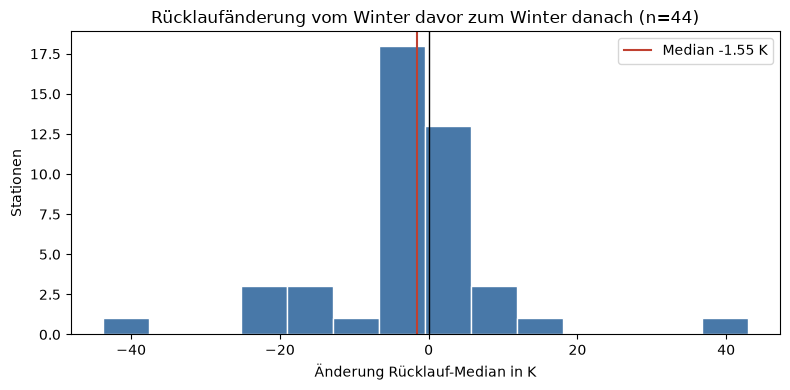

In [12]:
w = sub["d_rt_median"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(w, bins=14, color="#4878a8", edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.axvline(w.median(), color="#c04030", lw=1.5,
           label=f"Median {w.median():+.2f} K")
ax.set_title(f"Rücklaufänderung vom Winter davor zum Winter danach (n={len(w)})")
ax.set_xlabel("Änderung Rücklauf-Median in K")
ax.set_ylabel("Stationen")
ax.legend()
fig.tight_layout()
plt.show()

## 7 · Heizgradstunden: gleiche Jahreszeit heißt nicht gleich kalt

- Schieflage der Witterung zwischen den beiden Heizperioden.

In [13]:
print(f"Heizgradstunden je Winterfenster, Median ueber {len(sub)} Stationen")
print(f"  Winter davor  : {sub['heizgradstunden_vor'].median():,.0f} Kh")
print(f"  Winter danach : {sub['heizgradstunden_nach'].median():,.0f} Kh")
schief = (sub["heizgradstunden_nach"].median()
          / sub["heizgradstunden_vor"].median() - 1)
print(f"  Schieflage    : {schief:+.1%}")
print()
print(f"  Energie roh       Median {sub['d_energie_kwh'].median():+,.0f} kWh")
print(f"  Energie normiert  Median {sub['d_energie_je_kh'].median():+.4f} kWh/Kh")
print()
#Schieflage je Winterpaar, damit sie nicht in einem Gesamtmedian verschwindet
display(sub.groupby(["winter_vor_label", "winter_nach_label"])
        .agg(n=("meter", "size"),
             hgs_vor=("heizgradstunden_vor", "median"),
             hgs_nach=("heizgradstunden_nach", "median"))
        .assign(hgs_vor=lambda d: d["hgs_vor"].round(0),
                hgs_nach=lambda d: d["hgs_nach"].round(0),
                schieflage=lambda d: (d["hgs_nach"] / d["hgs_vor"] - 1).round(3)))

Heizgradstunden je Winterfenster, Median ueber 44 Stationen
  Winter davor  : 22,619 Kh
  Winter danach : 27,366 Kh
  Schieflage    : +21.0%

  Energie roh       Median +695 kWh
  Energie normiert  Median -0.0353 kWh/Kh



,,n,hgs_vor,hgs_nach,schieflage
winter_vor_label,winter_nach_label,,,,
2023/24,2024/25,42,22619.0,27366.0,0.210
2024/25,2025/26,2,27366.0,27174.0,-0.007


- Nachher-Winter rund 21 % kälter (Jahresvergleich: 19,3 %); rohe Energie damit unbrauchbar, `energie_je_kh` ist normiert.
- 42 der 44 Fälle liegen im Winterpaar 2023/24 gegen 2024/25, die zwei übrigen (2024/25 gegen 2025/26) nur durch die Nachlieferung.
- Die Schieflage lässt sich nicht herausmitteln, deshalb zählt die Kontrollgruppe (Abschnitt 10) mehr als der reine Vorher/Nachher-Test.

## 8 · Vierfeldertafel

In [14]:
v = jv.vierfeldertafel(sub)
n_tafel = int(v.to_numpy().sum())
print(f"Abgrenzung {VARIANTE}, n={n_tafel}, "
      f"Schwelle {RT_SCHWELLE:.0f} °C Rücklauf-Median")
display(v)
display((v / n_tafel * 100).round(1))

Abgrenzung kernwinter, n=44, Schwelle 50 °C Rücklauf-Median


zustand_nach,gut,schlecht
zustand_vor,,
gut,26,4
schlecht,5,9


zustand_nach,gut,schlecht
zustand_vor,,
gut,59.1,9.1
schlecht,11.4,20.5


In [15]:
ohne_wirkung = sub[(sub["zustand_vor"] == "schlecht")
                   & (sub["zustand_nach"] == "schlecht")]
print(f"schlecht -> schlecht: {len(ohne_wirkung)} von {n_tafel} "
      f"({len(ohne_wirkung) / n_tafel * 100:.0f} %)")
display(ohne_wirkung[["meter", "datum", "kategorie", "rt_median_vor",
                      "rt_median_nach", "d_rt_median", "weitere_begehung"]]
        .assign(datum=lambda d: d["datum"].dt.date)
        .sort_values("rt_median_nach", ascending=False)
        .round(1))

schlecht -> schlecht: 9 von 44 (20 %)


,meter,datum,kategorie,rt_median_vor,rt_median_nach,d_rt_median,weitere_begehung
28,80912182,2024-09-19,mittlere,71.1,69.6,-1.5,False
35,68956356,2024-09-19,geringe,59.7,60.8,1.1,False
5,68956352,2024-09-18,mittlere,57.9,58.1,0.2,False
25,72135442,2024-09-12,mittlere,69.2,54.4,-14.8,False
40,68956344,2024-09-20,viele,54.8,53.7,-1.1,False
48,80912170,2024-11-19,mittlere,53.0,52.7,-0.3,False
43,80912178,2024-09-23,keine,53.9,51.8,-2.1,False
50,68956345,2024-09-18,mittlere,54.9,50.9,-4.0,False
39,68956372,2024-10-14,viele,71.9,50.3,-21.6,False


- Schwelle 50 °C auf den Rücklauf-Median wie in Notebook 03, im Dashboard (`RT_YELLOW_MAX`) und in `rt_above_50_share_loaded`.

## 9 · Aufschlüsselung nach Änderungskategorie

In [16]:
def nach_kategorie(tab, spalte="d_rt_median"):
    teil = tab[tab["auswertbar"]]
    zeilen = []
    for kat, g in teil.groupby("kategorie", dropna=False):
        wk = g[spalte].dropna()
        p = (stats.wilcoxon(wk)[1]
             if len(wk) >= 5 and wk.abs().sum() > 0 else np.nan)
        zeilen.append({"kategorie": kat, "n": len(wk),
                       "median_K": wk.median() if len(wk) else np.nan,
                       "wilcoxon_p": p})
    return pd.DataFrame(zeilen).sort_values("n", ascending=False)


print("Rücklaufänderung je dokumentierter Änderungskategorie")
display(nach_kategorie(winter).round(3))

Rücklaufänderung je dokumentierter Änderungskategorie


,kategorie,n,median_K,wilcoxon_p
2,mittlere,25,-1.20,0.554
3,viele,14,-2.60,0.075
0,geringe,3,1.10,NaN
1,keine,2,-2.15,NaN


- Fallzahlen je Kategorie klein, teils nur zwei Stationen; keine Aussage, ob die Senkung mit dem Änderungsumfang wächst.

## 10 · Kontrollgruppe und Diff-in-Diff

- Kontrollgruppe: Zähler ohne Begehung, gleiche Winterlogik mit demselben Datum, also dieselbe Witterung und Netzfahrweise.
- Keine Kausalität, weil die besuchten Stationen nicht zufällig ausgewählt wurden.

In [17]:
kontroll_serien = {z: d for z, d in serien.items()
                   if z not in set(begehungen["meter"])}
print(f"Kontrollgruppe: {len(kontroll_serien)} Zaehler ohne dokumentierte Begehung")

DID_SPALTEN = ("d_rt_median", "d_rt_mean_loaded", "d_energie_je_kh")


def diff_in_diff(tab, variante, spalten=DID_SPALTEN):
    """Je Begehung die Kontrollbewegung im selben Winterpaar abziehen.

    Die Kontrollgruppe wird ueber die Fenstergrenzen gecacht. Im
    Kernwinter teilen sich alle Begehungen eines Herbstes dieselben
    Grenzen, sonst liefe die Rechnung unnoetig lange.
    """
    teil = tab[tab["auswertbar"]]
    cache, zeilen = {}, []
    for _, r in teil.iterrows():
        f = jv.winterfenster(r["datum"], variante)
        key = (f["vor_start"], f["vor_end"], f["nach_start"], f["nach_end"])
        if key not in cache:
            k = jv.winter_kontrollgruppe(kontroll_serien, r["datum"],
                                         variante, hdh)
            k = jv.winter_ausschlussbilanz(
                k, min_tagesabdeckung=MIN_TAGESABDECKUNG,
                min_fensteranteil=MIN_FENSTERANTEIL)
            cache[key] = k[k["auswertbar"]]
        k = cache[key]
        if len(k) < 5:
            continue
        zeile = {"meter": r["meter"], "datum": r["datum"],
                 "kategorie": r["kategorie"], "n_kontrolle": len(k)}
        for sp in spalten:
            zeile[f"{sp}_station"] = r[sp]
            zeile[f"{sp}_kontrolle"] = k[sp].median()
            zeile[f"did_{sp}"] = r[sp] - k[sp].median()
        zeilen.append(zeile)
    return pd.DataFrame(zeilen)


did = diff_in_diff(winter, VARIANTE)
print(f"{len(did)} Begehungen mit auswertbarer Kontrollgruppe, im Median "
      f"{did['n_kontrolle'].median():.0f} Kontrollstationen je Winterpaar")

Kontrollgruppe: 49 Zaehler ohne dokumentierte Begehung
42 Begehungen mit auswertbarer Kontrollgruppe, im Median 41 Kontrollstationen je Winterpaar


In [18]:
for sp in DID_SPALTEN:
    wd = did[f"did_{sp}"].dropna()
    p = stats.wilcoxon(wd)[1] if len(wd) >= 5 and wd.abs().sum() > 0 else np.nan
    print(f"did_{sp:18s} n={len(wd):2d}  Median {wd.median():+.3f}  "
          f"Q1 {wd.quantile(.25):+.3f}  Q3 {wd.quantile(.75):+.3f}  "
          f"Wilcoxon p = {p:.4f}")

print()
print("Rohwerte zur Einordnung (Median):")
for sp in DID_SPALTEN:
    print(f"  {sp:18s} Station {did[f'{sp}_station'].median():+.3f}   "
          f"Kontrolle {did[f'{sp}_kontrolle'].median():+.3f}")

did_d_rt_median        n=42  Median -1.900  Q1 -4.188  Q3 +0.450  Wilcoxon p = 0.0102
did_d_rt_mean_loaded   n=42  Median -0.530  Q1 -2.822  Q3 +0.590  Wilcoxon p = 0.0282
did_d_energie_je_kh    n=42  Median -0.009  Q1 -0.037  Q3 +0.008  Wilcoxon p = 0.0748

Rohwerte zur Einordnung (Median):
  d_rt_median        Station -1.600   Kontrolle +0.300
  d_rt_mean_loaded   Station -0.288   Kontrolle +0.241
  d_energie_je_kh    Station -0.035   Kontrolle -0.026


In [19]:
display(did.groupby("kategorie")["did_d_rt_median"]
        .agg(n="size", median="median").round(2)
        .sort_values("n", ascending=False))

,n,median
kategorie,,
mittlere,24,-1.65
viele,13,-3.40
geringe,3,0.80
keine,2,-2.45


- Kontrollgruppe im Median +0,3 K, Diff-in-Diff −1,9 K (n = 42, p ≈ 0,01); belastbarster Teil der Auswertung.
- Wer vorher auffällig war, hat mehr Spielraum nach unten.

## 11 · Sensitivität der Abgrenzung

- Erweiterte Abgrenzung September bis April und strenge Stundenabdeckung (ohne Zähler mit Tagesraster).

In [20]:
winter_sens = winter_auswertung(VARIANTE_SENS, serien, historien, begehungen)
winter_streng = winter_auswertung(VARIANTE, serien, historien, begehungen,
                                  min_coverage=MIN_COVERAGE)

zeilen = []
for name, tab in (("Kernwinter Dez-Feb", winter),
                  ("erweitert Sep-Apr", winter_sens),
                  (f"Kernwinter, Stunden >= {MIN_COVERAGE:.0%}", winter_streng)):
    teil = tab[tab["auswertbar"]]
    wk = teil["d_rt_median"].dropna()
    vt = jv.vierfeldertafel(teil)
    nt = int(vt.to_numpy().sum())
    zeilen.append({
        "abgrenzung": name, "n": len(wk),
        "median_d_rt_K": wk.median(),
        "wilcoxon_p": stats.wilcoxon(wk)[1] if len(wk) >= 5 else np.nan,
        "median_d_rt_mean_loaded_K": teil["d_rt_mean_loaded"].median(),
        "hgs_schieflage": (teil["heizgradstunden_nach"].median()
                           / teil["heizgradstunden_vor"].median() - 1),
        "schlecht_schlecht_%": vt.loc["schlecht", "schlecht"] / nt * 100 if nt else np.nan,
    })
display(pd.DataFrame(zeilen).round(4))

,abgrenzung,n,median_d_rt_K,wilcoxon_p,median_d_rt_mean_loaded_K,hgs_schieflage,schlecht_schlecht_%
0,Kernwinter Dez-Feb,44,-1.55,0.0875,-0.1841,0.2099,20.4545
1,erweitert Sep-Apr,44,-1.50,0.0202,-0.4969,0.1752,20.4545
2,"Kernwinter, Stunden >= 60%",23,-1.60,0.0495,-2.0876,0.2099,26.0870


- Ergebnis hängt nicht an der Abgrenzung: Kernwinter −1,55 K, erweitert −1,50 K, streng −1,60 K bei n = 23.

## 12 · Der alte und der neue Weg nebeneinander

- Jahresvergleich mit denselben Kennzahlen neu gerechnet und gegenübergestellt.

In [21]:
def alt_auswertung(L):
    """Der bisherige kalendergleiche Jahresvergleich, unveraendert."""
    tab = jv.jahresvergleich_tabelle(
        serien, begehungen, L, modus=jv.MODUS_KALENDER, hdh=hdh,
        meter_changes={z: [] for z in serien},
        begehungen_je_meter=begehungen_je_meter,
    )
    a = jv.abdeckung(begehungen, historien, L, modus=jv.MODUS_KALENDER)
    tab = tab.merge(a[["meter", "datum", "vollstaendig"]],
                    on=["meter", "datum"], how="left")
    tab["auswertbar"] = (tab["vollstaendig"]
                         & (tab["coverage_vor"] >= MIN_COVERAGE)
                         & (tab["coverage_nach"] >= MIN_COVERAGE))
    return tab


def alt_diff_in_diff(tab, L, spalten=DID_SPALTEN):
    teil = tab[tab["auswertbar"]]
    cache, zeilen = {}, []
    for _, r in teil.iterrows():
        key = pd.Timestamp(r["datum"])
        if key not in cache:
            k = jv.kontrollgruppe_tabelle(kontroll_serien, r["datum"], L, hdh=hdh)
            cache[key] = k[(k["coverage_vor"] >= MIN_COVERAGE)
                           & (k["coverage_nach"] >= MIN_COVERAGE)]
        k = cache[key]
        if len(k) < 5:
            continue
        zeile = {"meter": r["meter"], "n_kontrolle": len(k)}
        for sp in spalten:
            zeile[f"{sp}_station"] = r[sp]
            zeile[f"{sp}_kontrolle"] = k[sp].median()
            zeile[f"did_{sp}"] = r[sp] - k[sp].median()
        zeilen.append(zeile)
    return pd.DataFrame(zeilen)


alt_haupt = alt_auswertung(ALT_HAUPT_L)
alt_zweit = alt_auswertung(ALT_ZWEIT_L)
alt_did = alt_diff_in_diff(alt_haupt, ALT_HAUPT_L)
print(f"Jahresvergleich {ALT_HAUPT_L} Tage: "
      f"{int(alt_haupt['vollstaendig'].sum())} vollstaendig, "
      f"{int(alt_haupt['auswertbar'].sum())} auswertbar")
print(f"Jahresvergleich {ALT_ZWEIT_L} Tage: "
      f"{int(alt_zweit['vollstaendig'].sum())} vollstaendig, "
      f"{int(alt_zweit['auswertbar'].sum())} auswertbar")

Jahresvergleich 270 Tage: 34 vollstaendig, 24 auswertbar
Jahresvergleich 180 Tage: 44 vollstaendig, 29 auswertbar


In [22]:
def kennwerte(name, tab, did_tab):
    teil = tab[tab["auswertbar"]]
    wk = teil["d_rt_median"].dropna()
    zeile = {"variante": name, "n": len(wk),
             "median_d_rt_K": wk.median(),
             "wilcoxon_p": stats.wilcoxon(wk)[1] if len(wk) >= 5 else np.nan,
             "hgs_schieflage": (teil["heizgradstunden_nach"].median()
                                / teil["heizgradstunden_vor"].median() - 1)}
    if did_tab is not None and len(did_tab):
        wd = did_tab["did_d_rt_median"].dropna()
        zeile.update({"n_did": len(wd), "did_median_K": wd.median(),
                      "did_p": stats.wilcoxon(wd)[1] if len(wd) >= 5 else np.nan,
                      "kontrolle_d_rt_K": did_tab["d_rt_median_kontrolle"].median()})
    return zeile


vergleich = pd.DataFrame([
    kennwerte(f"alt: Jahr {ALT_HAUPT_L} Tage kalendergleich", alt_haupt, alt_did),
    kennwerte(f"alt: Jahr {ALT_ZWEIT_L} Tage kalendergleich", alt_zweit, None),
    kennwerte(f"neu: Winter {VARIANTE}", winter, did),
])
display(vergleich.round(4))

,variante,n,median_d_rt_K,wilcoxon_p,hgs_schieflage,n_did,did_median_K,did_p,kontrolle_d_rt_K
0,alt: Jahr 270 Tage kalendergleich,24,-1.75,0.0108,0.1926,22.0,-1.9,0.0009,0.1
1,alt: Jahr 180 Tage kalendergleich,29,-1.20,0.0306,0.1913,NaN,NaN,NaN,NaN
2,neu: Winter kernwinter,44,-1.55,0.0875,0.2099,42.0,-1.9,0.0102,0.3


- Bestätigt den bisherigen Befund, verstärkt ihn nicht: Fallzahl 44 statt 24, Diff-in-Diff unverändert −1,9 K.
- Median −1,55 statt −1,75 K, gepaarter p-Wert 0,0875 statt 0,0108: mehr Fälle, etwas kleinerer Effekt, mehr Streuung.

## 13 · Markierte Sonderfälle

In [23]:
sonder = sub[sub["weitere_begehung"] | sub["meter_change"]]
print(f"{len(sonder)} von {len(sub)} auswertbaren Begehungen sind markiert")
if len(sonder):
    display(sonder[["meter", "datum", "kategorie", "weitere_begehung",
                    "meter_change", "d_rt_median", "d_energie_je_kh"]]
            .assign(datum=lambda d: d["datum"].dt.date).round(3))

ohne = sub[~(sub["weitere_begehung"] | sub["meter_change"])]
wo = ohne["d_rt_median"].dropna()
print(f"\nohne die markierten Faelle: n={len(wo)}, Median {wo.median():+.2f} K, "
      f"Wilcoxon p = {stats.wilcoxon(wo)[1]:.4f}")

0 von 44 auswertbaren Begehungen sind markiert

ohne die markierten Faelle: n=44, Median -1.55 K, Wilcoxon p = 0.0875


## 14 · Ergebnistabelle sichern

In [24]:
ziel = Path("..") / "data" / "processed"
ziel.mkdir(parents=True, exist_ok=True)

#keine Adressen, nur Zaehlernummern - data/processed ist zusaetzlich gitignored
spalten = (["meter", "datum", "variante", "winter_vor_label",
            "winter_nach_label", "angeschnitten", "fensteranteil", "kategorie",
            "tagesabdeckung_vor", "tagesabdeckung_nach",
            "coverage_vor", "coverage_nach", "vollstaendig",
            "ausschlussgrund", "auswertbar", "weitere_begehung", "meter_change"]
           + [f"{k}_{s}" for k in jv.KENNZAHLEN for s in ("vor", "nach")]
           + [f"d_{k}" for k in jv.KENNZAHLEN]
           + ["zustand_vor", "zustand_nach"])

for name, tab in (("kernwinter", winter), ("erweitert", winter_sens)):
    pfad = ziel / f"wintervergleich_{name}.csv"
    tab[[c for c in spalten if c in tab.columns]].to_csv(pfad, index=False)
    print(f"{pfad.name}: {len(tab)} Zeilen")

wintervergleich_kernwinter.csv: 53 Zeilen
wintervergleich_erweitert.csv: 53 Zeilen


## 15 · Gegenprobe ohne Nachlieferung

- Dieselbe Auswertung mit den fünf Nachlieferungszählern am gemeinsamen Exportende 11.07.2025 abgeschnitten.

In [25]:
ODS_METER = nb00.lange_reihen(serien)
ende_gemeinsam = max(d.index[-1] for z, d in serien.items()
                     if z not in ODS_METER)
print(f"Zaehler mit Nachlieferung: {ODS_METER}")
print(f"gemeinsames Exportende der uebrigen: {ende_gemeinsam.date()}")

serien_kurz = dict(serien)
historien_kurz = dict(historien)
for zid in ODS_METER:
    d = serien[zid]
    serien_kurz[zid] = d[d.index <= ende_gemeinsam]
    historien_kurz[zid] = (d.index[0].normalize(),
                           serien_kurz[zid].index[-1].normalize())
    print(f"{zid}: {historien[zid][0].date()}..{historien[zid][1].date()}, "
          f"integrierte Zaehlerstaende: "
          f"{d.attrs['zaehlerstand_integriert']} Stunden")


Zaehler mit Nachlieferung: [68956347, 68956371, 68956372, 72167783, 80912172]
gemeinsames Exportende der uebrigen: 2025-07-11
68956347: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 19211 Stunden
68956371: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 19022 Stunden
68956372: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 19183 Stunden
72167783: 2021-11-01..2026-07-20, integrierte Zaehlerstaende: 19212 Stunden
80912172: 2023-09-08..2026-07-20, integrierte Zaehlerstaende: 19082 Stunden


In [26]:
winter_kurz = winter_auswertung(VARIANTE, serien_kurz, historien_kurz,
                                begehungen)
sub_kurz = winter_kurz[winter_kurz["auswertbar"]]

paare_kurz = set(zip(sub_kurz["meter"], sub_kurz["datum"]))
nur_voll = {(m, d) for m, d in zip(sub["meter"], sub["datum"])
            if (m, d) not in paare_kurz}
print(f"auswertbar mit Nachlieferung (oben): {len(sub)}")
print(f"auswertbar ohne Nachlieferung      : {len(sub_kurz)}")
print(f"nur mit Nachlieferung rechenbar    : {len(nur_voll)}")

if nur_voll:
    neu_tab = sub[[(m, d) in nur_voll
                   for m, d in zip(sub["meter"], sub["datum"])]]
    display(neu_tab[["meter", "datum", "winter_vor_label", "winter_nach_label",
                     "rt_median_vor", "rt_median_nach", "d_rt_median",
                     "d_dt_mean_loaded", "d_energie_je_kh"]]
            .assign(datum=lambda d: d["datum"].dt.date).round(2))

wk = sub_kurz["d_rt_median"].dropna()
print(f"\nmit Nachlieferung : n={len(w)}, Median {w.median():+.2f} K, "
      f"Wilcoxon p = {stats.wilcoxon(w)[1]:.4f}")
print(f"ohne Nachlieferung: n={len(wk)}, Median {wk.median():+.2f} K, "
      f"Wilcoxon p = {stats.wilcoxon(wk)[1]:.4f}")


auswertbar mit Nachlieferung (oben): 44
auswertbar ohne Nachlieferung      : 42
nur mit Nachlieferung rechenbar    : 2


,meter,datum,winter_vor_label,winter_nach_label,rt_median_vor,rt_median_nach,d_rt_median,d_dt_mean_loaded,d_energie_je_kh
6,68956371,2025-09-16,2024/25,2025/26,30.3,34.25,3.95,-4.1,0.01
13,72167783,2025-09-11,2024/25,2025/26,27.1,70.00,42.90,NaN,-0.55



mit Nachlieferung : n=44, Median -1.55 K, Wilcoxon p = 0.0875
ohne Nachlieferung: n=42, Median -1.60 K, Wilcoxon p = 0.0258


- Nachlieferung bringt zwei zusätzliche Fälle (68956371 und 72167783, Begehung September 2025), beide mit steigendem Rücklauf (+4,0 K und +42,9 K).
- 72167783 nimmt im Winter 2025/26 praktisch keine Wärme ab, Rücklauf auf Vorlaufniveau (Median 70 °C): Betriebszustand, keine Maßnahmenwirkung.
- Mit Nachlieferung n = 44, −1,55 K, p ≈ 0,09; ohne n = 42, −1,60 K, p ≈ 0,03; nur der p-Wert reagiert.

## Zusammenfassung & Bewertung

Ergebnis
- 44 Begehungen an 43 Zählern auswertbar (unter 60 % Tagesabdeckung ausgeschlossen)
- Rücklauf-Median sinkt um 1,55 K (p ≈ 0,09), ohne Nachlieferung um 1,60 K (p ≈ 0,03)
- Diff-in-Diff gegen 49 Zähler ohne Begehung −1,9 K (p ≈ 0,01)
- vorher und nachher „schlecht“ (Schwelle 50 °C): 9 von 44, Kandidaten für eine erneute Prüfung

Belastbar
- Rückgang bleibt nach Abzug der Kontrollgruppe, konsistent mit einer Wirkung der Begehungen
- unabhängig von der Winterabgrenzung

Schwach
- fast alle Fälle in einem Winterpaar mit 21 % kälterem Nachher-Winter
- Änderungskategorien zu dünn besetzt
- witterungsnormierte Energie im Diff-in-Diff ohne klares Muster (−0,009 kWh/Kh, p ≈ 0,07)
- Kontrollgruppe nicht zufällig, deshalb nur „konsistent mit“

Offen
- Winter 2025/26 fehlt für 95 der 100 Zähler
- Winterabgrenzung und Abdeckungsschwellen noch festzulegen